In [2]:
# import libraries
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:

import sqlite3
import pandas as pd

db_path = r"C:\Users\Pooja\Desktop\clustering (1).db"

with sqlite3.connect(db_path) as conn:
    # Inspect only 5 records first
    df = pd.read_sql_query(
        'SELECT * FROM "supermarket_data" ' ,
        conn
    )

df.head()



,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name
0,1253241,152060,6,1,20,23.0,115,2,1,7,beverages,water seltzer sparkling water
1,3058717,44755,2,1,15,30.0,37,4,0,1,frozen,ice cream ice
2,2252307,169119,12,4,15,9.0,123,19,0,4,produce,packaged vegetables fruits
3,188072,162421,3,4,11,30.0,117,5,0,19,snacks,nuts seeds dried fruit
4,2627597,172693,19,0,23,5.0,17,8,0,13,pantry,baking ingredients


In [27]:
df.columns

Index(['order_id', 'user_id', 'order_number', 'order_dow', 'order_hour_of_day',
       'days_since_prior_order', 'product_id', 'add_to_cart_order',
       'reordered', 'department_id', 'department', 'product_name'],
      dtype='object')

In [28]:
df.iloc[0]

order_id                                        1253241
user_id                                          152060
order_number                                          6
order_dow                                             1
order_hour_of_day                                    20
days_since_prior_order                             23.0
product_id                                          115
add_to_cart_order                                     2
reordered                                             1
department_id                                         7
department                                    beverages
product_name              water seltzer sparkling water
Name: 0, dtype: object

In [29]:
df.isna().sum()

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    61437
product_id                    0
add_to_cart_order             0
reordered                     0
department_id                 0
department                    0
product_name                  0
dtype: int64

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 12 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   order_id                1000000 non-null  int64  
 1   user_id                 1000000 non-null  int64  
 2   order_number            1000000 non-null  int64  
 3   order_dow               1000000 non-null  int64  
 4   order_hour_of_day       1000000 non-null  int64  
 5   days_since_prior_order  938563 non-null   float64
 6   product_id              1000000 non-null  int64  
 7   add_to_cart_order       1000000 non-null  int64  
 8   reordered               1000000 non-null  int64  
 9   department_id           1000000 non-null  int64  
 10  department              1000000 non-null  object 
 11  product_name            1000000 non-null  object 
dtypes: float64(1), int64(9), object(2)
memory usage: 91.6+ MB


In [31]:
df.describe()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,938563.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,1.705091e+06,103048.786172,17.137525,2.734707,13.439826,11.394532,71.173460,8.362221,0.590152,9.923752
std,9.853287e+05,59530.013137,17.511122,2.094253,4.238804,8.977931,38.221046,7.146741,0.491806,6.281661
min,1.000000e+01,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
25%,8.516880e+05,51542.000000,5.000000,1.000000,10.000000,5.000000,31.000000,3.000000,0.000000,4.000000
50%,1.702068e+06,102637.000000,11.000000,3.000000,13.000000,8.000000,83.000000,6.000000,1.000000,9.000000
75%,2.555671e+06,154668.000000,24.000000,5.000000,16.000000,15.000000,107.000000,11.000000,1.000000,16.000000
max,3.421080e+06,206209.000000,100.000000,6.000000,23.000000,30.000000,134.000000,137.000000,1.000000,21.000000


In [32]:
df.duplicated().sum()

np.int64(0)

In [33]:
print("Dataset shape:", df.shape)
print("Unique customers:", df["user_id"].nunique())
print("Unique orders:", df["order_id"].nunique())
print("Unique products:", df["product_id"].nunique())

print(df.head())

Dataset shape: (1000000, 12)
Unique customers: 101335
Unique orders: 188452
Unique products: 134
   order_id  user_id  order_number  order_dow  order_hour_of_day  \
0   1253241   152060             6          1                 20   
1   3058717    44755             2          1                 15   
2   2252307   169119            12          4                 15   
3    188072   162421             3          4                 11   
4   2627597   172693            19          0                 23   

   days_since_prior_order  product_id  add_to_cart_order  reordered  \
0                    23.0         115                  2          1   
1                    30.0          37                  4          0   
2                     9.0         123                 19          0   
3                    30.0         117                  5          0   
4                     5.0          17                  8          0   

   department_id department                   product_name  
0     

In [4]:

print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nReorder distribution:")
print(df["reordered"].value_counts(normalize=True).round(3))

print("\nOrder day distribution:")
print(df["order_dow"].value_counts().sort_index())

print("\nShopping hour distribution:")
print(df["order_hour_of_day"].value_counts().sort_index())

print("\nDays since prior order:")
print(df["days_since_prior_order"].describe())

Missing values:
 order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    61437
product_id                    0
add_to_cart_order             0
reordered                     0
department_id                 0
department                    0
product_name                  0
dtype: int64
Duplicate rows: 0

Reorder distribution:
reordered
1    0.59
0    0.41
Name: proportion, dtype: float64

Order day distribution:
order_dow
0    194233
1    172751
2    130082
3    117931
4    116079
5    129861
6    139063
Name: count, dtype: int64

Shopping hour distribution:
order_hour_of_day
0      6652
1      3632
2      2059
3      1448
4      1597
5      2855
6      8964
7     26889
8     52728
9     74265
10    85835
11    84533
12    81004
13    82737
14    83434
15    82413
16    78312
17    63656
18    50886
19    38963
20    30766
21    24189
22    20147
23    12036
Na

In [6]:
import pandas as pd
import numpy as np

customer_features = df.groupby("user_id").agg(
    total_orders=("order_id", "nunique"),
    total_items=("product_id", "count"),
    unique_products=("product_id", "nunique"),
    reorder_ratio=("reordered", "mean"),
    last_order_number=("order_number", "max"),
    avg_days_between_orders=("days_since_prior_order", "mean"),
    avg_cart_position=("add_to_cart_order", "mean")
)

customer_features["avg_basket_size"] = (
    customer_features["total_items"] /
    customer_features["total_orders"]
)

print("Customer feature shape:", customer_features.shape)
display(customer_features.describe().round(2))
display(customer_features.head())

Customer feature shape: (101335, 8)


,total_orders,total_items,unique_products,reorder_ratio,last_order_number,avg_days_between_orders,avg_cart_position,avg_basket_size
count,101335.00,101335.00,101335.00,101335.00,101335.00,95199.00,101335.00,101335.00
mean,1.86,9.87,6.72,0.54,16.23,13.07,6.01,5.26
std,1.35,10.16,5.19,0.34,17.63,9.14,3.78,3.64
min,1.00,1.00,1.00,0.00,1.00,0.00,1.00,1.00
25%,1.00,3.00,3.00,0.26,4.00,6.00,3.29,2.71
50%,1.00,7.00,5.00,0.57,10.00,10.00,5.23,4.40
75%,2.00,13.00,9.00,0.82,22.00,19.14,7.89,7.00
max,14.00,231.00,47.00,1.00,100.00,30.00,48.61,51.00


,total_orders,total_items,unique_products,reorder_ratio,last_order_number,avg_days_between_orders,avg_cart_position,avg_basket_size
user_id,,,,,,,,
2,2,7,4,0.285714,3,8.000000,3.000000,3.5
3,3,9,8,0.333333,11,11.666667,4.000000,3.0
7,1,14,12,0.785714,3,30.000000,11.285714,14.0
10,1,13,8,0.230769,4,14.000000,15.538462,13.0
11,1,8,7,0.375000,5,30.000000,7.000000,8.0


In [7]:
print(
    "Customers where total_orders != last_order_number:",
    (customer_features["total_orders"] !=
     customer_features["last_order_number"]).sum()
)

print(
    customer_features[
        ["total_orders", "last_order_number"]
    ].corr()
)

Customers where total_orders != last_order_number: 94811
                   total_orders  last_order_number
total_orders           1.000000           0.738174
last_order_number      0.738174           1.000000


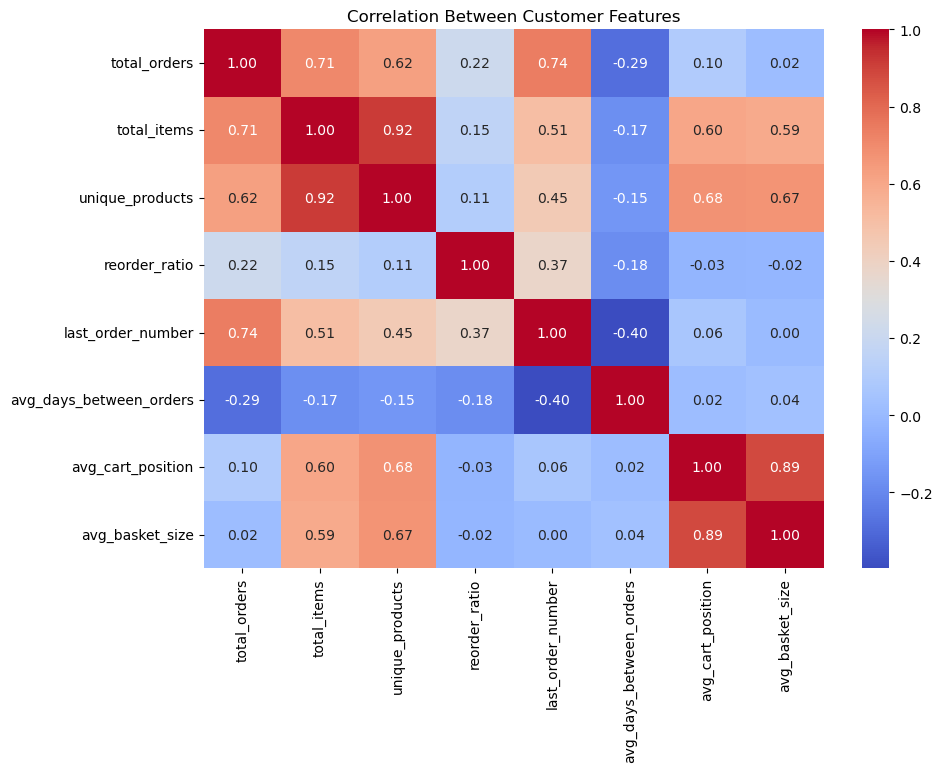

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    customer_features.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Customer Features")
plt.show()

In [9]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

features = [
    "total_orders",
    "total_items",
    "unique_products",
    "reorder_ratio",
    "avg_days_between_orders",
    "avg_basket_size"
]

X = customer_features[features].copy()

# Create an indicator for missing order intervals
X["interval_missing"] = (
    X["avg_days_between_orders"].isna().astype(int)
)

# Impute missing intervals with the median
X["avg_days_between_orders"] = (
    X["avg_days_between_orders"].fillna(
        X["avg_days_between_orders"].median()
    )
)

# Reduce skew in count-like features
log_features = [
    "total_orders",
    "total_items",
    "unique_products",
    "avg_basket_size",
    "avg_days_between_orders"
]

X[log_features] = np.log1p(X[log_features])

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features used:", X.columns.tolist())
print("Scaled shape:", X_scaled.shape)
print("Missing values:", X.isna().sum().sum())

Features used: ['total_orders', 'total_items', 'unique_products', 'reorder_ratio', 'avg_days_between_orders', 'avg_basket_size', 'interval_missing']
Scaled shape: (101335, 7)
Missing values: 0


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": score
    })

results_df = pd.DataFrame(results)
display(results_df)

,k,inertia,silhouette_score
0,2,500542.677677,0.264502
1,3,389798.419757,0.305946
2,4,318485.143242,0.265054
3,5,278890.143796,0.257426
4,6,248511.690265,0.261884
5,7,227639.661162,0.257222
6,8,209351.161957,0.245844


In [11]:
from sklearn.cluster import KMeans

best_k = 3

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_features["cluster"] = final_model.fit_predict(X_scaled)

print(customer_features["cluster"].value_counts().sort_index())

cluster
0    47543
1    47656
2     6136
Name: count, dtype: int64


In [12]:
profile = customer_features.groupby("cluster").agg(
    customers=("total_orders", "size"),
    avg_orders=("total_orders", "mean"),
    avg_items=("total_items", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    avg_days_between_orders=("avg_days_between_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean")
).round(2)

profile["customer_percentage"] = (
    profile["customers"] /
    len(customer_features) * 100
).round(2)

display(profile)

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,customer_percentage
cluster,,,,,,,,
0,47543,1.25,3.63,3.07,0.55,14.46,3.08,46.92
1,47656,2.57,16.70,10.67,0.59,11.69,7.45,47.03
2,6136,1.00,5.19,4.31,0.00,NaN,5.19,6.06


In [13]:
print(
    customer_features["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

cluster
0    46.92
1    47.03
2     6.06
Name: proportion, dtype: float64


In [14]:
# Check whether Cluster 2 contains only single-order customers
display(
    customer_features.groupby("cluster").agg(
        customers=("total_orders", "size"),
        min_orders=("total_orders", "min"),
        max_orders=("total_orders", "max"),
        avg_reorder_ratio=("reorder_ratio", "mean"),
        missing_intervals=(
            "avg_days_between_orders",
            lambda s: s.isna().sum()
        )
    )
)

,customers,min_orders,max_orders,avg_reorder_ratio,missing_intervals
cluster,,,,,
0,47543,1,7,0.550364,0
1,47656,1,14,0.591583,0
2,6136,1,1,0.000000,6136


In [15]:
# Customer counts by order count and cluster
display(pd.crosstab(
    customer_features["cluster"],
    customer_features["total_orders"]
))

total_orders,1,2,3,4,5,6,7,8,9,10,11,12,13,14
cluster,,,,,,,,,,,,,,
0,37481,8372,1417,241,28,3,1,0,0,0,0,0,0,0
1,13193,15108,9106,4830,2561,1406,760,345,209,83,35,14,5,1
2,6136,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
display(
    customer_features.groupby("cluster").agg(
        avg_last_order_number=("last_order_number", "mean"),
        min_last_order_number=("last_order_number", "min"),
        max_last_order_number=("last_order_number", "max")
    )
)

,avg_last_order_number,min_last_order_number,max_last_order_number
cluster,,,
0,10.870559,2,99
1,23.538190,2,100
2,1.000000,1,1


In [17]:
# Use the same feature set, but exclude the missingness indicator
X_compare = X.drop(columns=["interval_missing"], errors="ignore")

scaler_compare = StandardScaler()
X_compare_scaled = scaler_compare.fit_transform(X_compare)

model_compare = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_compare = model_compare.fit_predict(X_compare_scaled)

print("Cluster sizes without missingness indicator:")
print(pd.Series(labels_compare).value_counts().sort_index())

print(
    "Silhouette score:",
    silhouette_score(
        X_compare_scaled,
        labels_compare,
        sample_size=5000,
        random_state=42
    )
)

Cluster sizes without missingness indicator:
0    38011
1    26360
2    36964
Name: count, dtype: int64
Silhouette score: 0.2421218757610193


In [ ]:
# Use these names in project report, subject to the final validation:
# Cluster	Suggested name	Business objective
# 0	Lower-frequency, smaller-basket customers:	Encourage repeat orders and relevant complementary purchases
# 1	Larger-basket, repeat-active customers:	Increase retention, cross-selling and loyalty
# 2	First-order customers:	Encourage the second purchase and establish repeat behavio

In [ ]:
# Conclusion:
# Customer segmentation was performed using K-Means clustering on customer-level purchasing features derived from the supermarket dataset. 
# The analysis covered 101,335 customers and considered order frequency, purchase volume, product variety, reorder ratio, basket size and order 
# intervals.
# Three clusters were selected as the leading solution after comparing candidate cluster counts. The model achieved a silhouette score of 
# approximately 0.306, indicating moderate cluster separation.
# The resulting segments represent lower-frequency, smaller-basket customers; larger-basket, repeat-active customers; and first-order customers. 
# These segments can support targeted retention campaigns, complementary-product promotions, loyalty initiatives and second-purchase incentives.
#The results should be interpreted in light of the dataset's coverage of customer order histories. Further validation and monitoring are 
# recommended before using the segments for operational decisions.

In [18]:
# Summarize customer behavior for each cluster
cluster_profile = customer_features.groupby("cluster").agg(
    customers=("total_orders", "size"),
    avg_orders=("total_orders", "mean"),
    avg_items=("total_items", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    avg_days_between_orders=("avg_days_between_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean"),
    avg_order_sequence=("last_order_number", "mean")
)

# Calculate percentage of customers in each cluster
cluster_profile["customer_percentage"] = (
    cluster_profile["customers"]
    / len(customer_features) * 100
)

# Round numerical values for readability
cluster_profile = cluster_profile.round(2)

display(cluster_profile)

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,avg_order_sequence,customer_percentage
cluster,,,,,,,,,
0,47543,1.25,3.63,3.07,0.55,14.46,3.08,10.87,46.92
1,47656,2.57,16.70,10.67,0.59,11.69,7.45,23.54,47.03
2,6136,1.00,5.19,4.31,0.00,NaN,5.19,1.00,6.06


In [19]:
cluster_names = {
    0: "Lower-frequency, smaller-basket customers",
    1: "Larger-basket, repeat-active customers",
    2: "First-order customers"
}

cluster_profile["segment_name"] = (
    cluster_profile.index.map(cluster_names)
)

display(cluster_profile)

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,avg_order_sequence,customer_percentage,segment_name
cluster,,,,,,,,,,
0,47543,1.25,3.63,3.07,0.55,14.46,3.08,10.87,46.92,"Lower-frequency, smaller-basket customers"
1,47656,2.57,16.70,10.67,0.59,11.69,7.45,23.54,47.03,"Larger-basket, repeat-active customers"
2,6136,1.00,5.19,4.31,0.00,NaN,5.19,1.00,6.06,First-order customers


In [20]:
cluster_profile.to_csv(
    "supermarket_cluster_profile.csv",
    index=True
)

In [ ]:
# Supermarket Customer Segmentation Using Machine Learning:
# Tools: Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, SQL/SQLite
# 1- Analyzed 1 million supermarket product-order records covering 101,335 unique customers to identify purchasing patterns.
# 2- Performed data quality checks, customer-level feature engineering, missing-value treatment and feature scaling.
# 3- Applied K-Means clustering and compared candidate cluster counts using inertia and silhouette scores.
# 4- Identified three preliminary customer segments based on recorded order frequency, basket size, reorder behavior and 
# order history, achieving a silhouette score of approximately 0.306.
# Translated customer profiles into business recommendations for targeted promotions, repeat-purchase campaigns and customer retention.

In [25]:
import os
import matplotlib.pyplot as plt

os.makedirs("visualizations", exist_ok=True)

print("Visualization folder created!")
print("Current folder:", os.getcwd())

Visualization folder created!
Current folder: C:\Users\Pooja


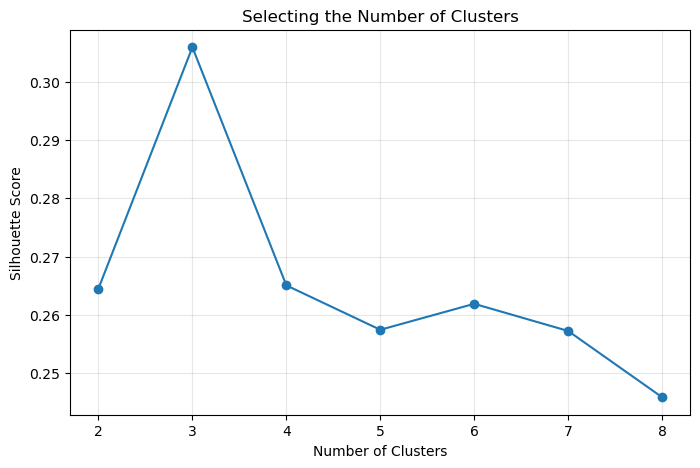

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Selecting the Number of Clusters")
plt.xticks(results_df["k"])
plt.grid(True, alpha=0.3)

plt.savefig(
    "visualizations/silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

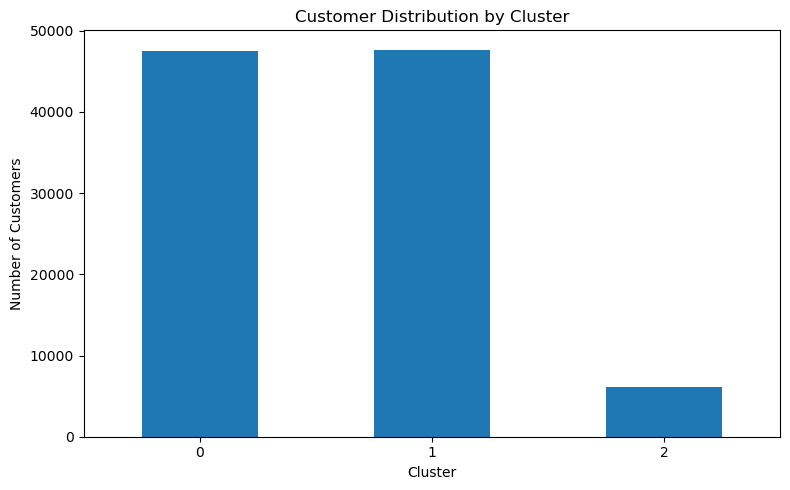

In [26]:
cluster_counts = (
    customer_features["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution by Cluster")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "visualizations/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

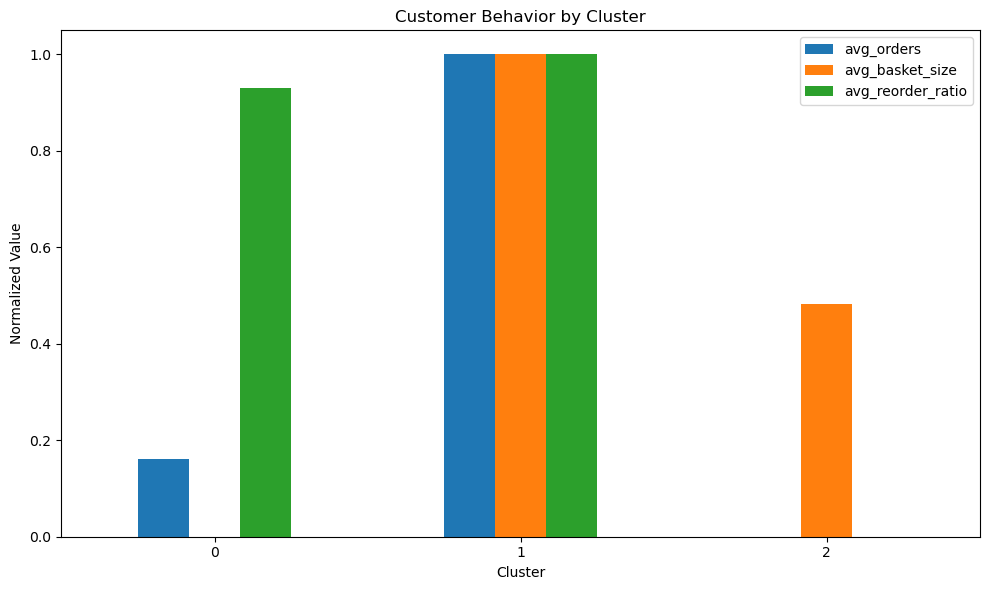

In [28]:
cluster_profile = customer_features.groupby("cluster").agg(
    avg_orders=("total_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean")
)

# Normalize values for easier visual comparison
profile_normalized = (
    cluster_profile - cluster_profile.min()
) / (
    cluster_profile.max() - cluster_profile.min()
).replace(0, 1)

profile_normalized.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Cluster")
plt.ylabel("Normalized Value")
plt.title("Customer Behavior by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "visualizations/cluster_behavior_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
print(os.listdir("visualizations"))

['cluster_behavior_comparison.png', 'cluster_distribution.png', 'silhouette_scores.png']


In [30]:
cluster_profile.to_csv(
    "cluster_profile.csv",
    index=True
)

print("Cluster profile saved successfully!")

Cluster profile saved successfully!


In [31]:
print(os.path.exists("cluster_profile.csv"))

True


In [32]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")

for file in os.listdir():
    print(file)

Current folder: C:\Users\Pooja

Files in this folder:
.anaconda
.android
.cache
.conda
.continuum
.gitconfig
.ipynb_checkpoints
.ipython
.jupyter
.keras
.lesshst
.matplotlib
.streamlit
.virtual_documents
.vscode
.wslconfig
anaconda3
AppData
Application Data
Assignment-12.ipynb
Assignment-9.ipynb
Assignment10.ipynb
Assignment11.ipynb
Clustering(1).db
cluster_profile.csv
Contacts
Cookies
Desktop
Documents
Downloads
e-commerce chat bot.ipynb
ecommerce-security-chatbot
ecommerce_security_chatbot
Favorites
final_confusion_matrices.csv
heartdisease.ipynb
Heart_Disease_Final_Model.ipynb.ipynb
heart_logistic_final_pipeline.pkl
heart_logistic_final_threshold.pkl
heart_logistic_pipeline.pkl
heart_model_thresholds.pkl
heart_random_forest_pipeline.pkl
heart_rf_final_pipeline.pkl
heart_rf_final_threshold.pkl
IntelGraphicsProfiles
Links
Local Settings
model_classifier.pkl
Music
My Documents
NetHood
New folder
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{ecd99daa-4eab-11f1-ab5e-00155d798f58}

In [33]:
import glob
import os

for file in glob.glob("*.ipynb"):
    print(file)

Assignment-12.ipynb
Assignment-9.ipynb
Assignment10.ipynb
Assignment11.ipynb
e-commerce chat bot.ipynb
heartdisease.ipynb
Heart_Disease_Final_Model.ipynb.ipynb
project.ipynb
Regression 1.ipynb
Regression2.ipynb
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
